    Model  Train Loss  Val Loss       MAE      RMSE     MAPE  Time (s)
SimpleRNN    0.004964  0.003621  8.610008 10.643314 0.051662      4.79
     LSTM    0.017363  0.017890 18.418104 21.046108 0.111059      4.75


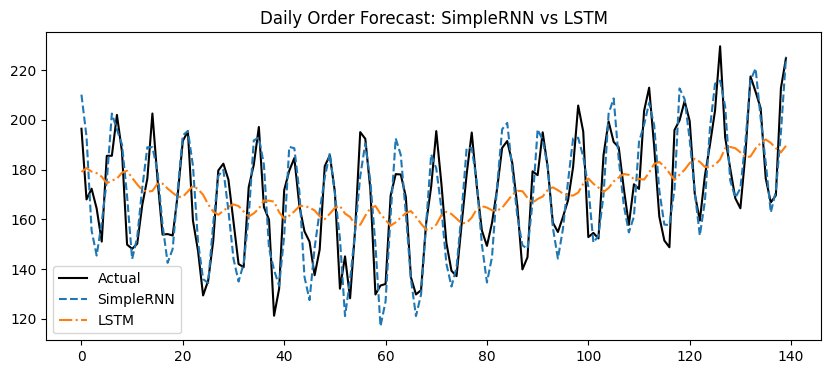

In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
from tensorflow.keras import layers, models

days = np.arange(730)
orders = 200 + 40*np.sin(2*np.pi*days/365) + 25*np.sin(2*np.pi*days/7) + np.random.normal(0, 8, len(days))
scaler = MinMaxScaler()
scaled = scaler.fit_transform(orders.reshape(-1, 1))

win = 30
X = np.array([scaled[i:i+win] for i in range(len(scaled) - win)])
y = np.array([scaled[i+win] for i in range(len(scaled) - win)])
split = int(0.8 * len(X))
X_tr, X_te, y_tr, y_te = X[:split], X[split:], y[:split], y[split:]
actual = scaler.inverse_transform(y_te)

results = []
preds = {}
for name, rnn_cls in [("SimpleRNN", layers.SimpleRNN), ("LSTM", layers.LSTM)]:
    m = models.Sequential([layers.Input(shape=(win, 1)), rnn_cls(32), layers.Dense(1)])
    m.compile(optimizer="adam", loss="mse")
    t0 = time.time()
    hist = m.fit(X_tr, y_tr, validation_split=0.2, epochs=15, batch_size=32, verbose=0)
    dt = time.time() - t0
    p = scaler.inverse_transform(m.predict(X_te, verbose=0))
    preds[name] = p
    results.append({
        "Model": name, "Train Loss": hist.history["loss"][-1],
        "Val Loss": hist.history["val_loss"][-1],
        "MAE": mean_absolute_error(actual, p),
        "RMSE": root_mean_squared_error(actual, p),
        "MAPE": mean_absolute_percentage_error(actual, p),
        "Time (s)": round(dt, 2)
    })

df_res = pd.DataFrame(results)
print(df_res.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.plot(actual, label="Actual", color="black")
plt.plot(preds["SimpleRNN"], label="SimpleRNN", linestyle="--")
plt.plot(preds["LSTM"], label="LSTM", linestyle="-.")
plt.title("Daily Order Forecast: SimpleRNN vs LSTM"); plt.legend(); plt.show()